# Full diffusion-unrolled RDBM: 2×, 4×

This report covers the completed rates from the from-scratch, end-to-end model.
Unlike the earlier three-stage RDBM-derived network, this architecture preserves
all ten reverse-diffusion refinements and follows every refinement with a
six-iteration differentiable CG-SENSE solve.

Each rate is trained independently for 50 passes. Ten checkpoints are screened
using validation PSNR before the selected checkpoint is evaluated once on test.

In [1]:
from pathlib import Path
from html import escape
import json, os, re
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_ROOT = Path(os.environ.get('MRI_DATA_ROOT', '/data/david_agyei/nyu-dataset'))
OUTPUT_ROOT = Path(os.environ.get('FULL_UNROLLED_OUTPUT_ROOT', DATA_ROOT/'derived'))
RATES = (2, 4)
METHOD = 'diffusion_unrolled_rdbm'
def read_json(path): return json.loads(Path(path).read_text())
def artifacts(rate):
    run=OUTPUT_ROOT/f'full_diffusion_unrolled_rdbm_{rate}x_scratch'; evaluation=run/'evaluation'
    selection=read_json(evaluation/'best_validation_checkpoint.json')
    test_dir=evaluation/'test'/f"step-{selection['checkpoint_step']:07d}"
    return run,selection,test_dir,read_json(test_dir/'summary.json')
def show_table(rows,columns,precision=4,bold_best=None):
    bold_best=bold_best or {}; best={}
    for key,direction in bold_best.items():
        values=[row[key] for row in rows if isinstance(row[key],(int,float)) and np.isfinite(row[key])]
        best[key]=(max if direction=='max' else min)(values)
    def render(value): return f'{value:.{precision}f}' if isinstance(value,float) else escape(str(value))
    header=''.join(f'<th style="text-align:left;padding:4px 10px">{escape(label)}</th>' for key,label in columns)
    def cell(row,key):
        value=render(row[key])
        if key in best and np.isclose(row[key],best[key]): value=f'<strong>{value}</strong>'
        return f'<td style="padding:4px 10px">{value}</td>'
    body=''.join('<tr>'+''.join(cell(row,key) for key,label in columns)+'</tr>' for row in rows)
    display(HTML(f'<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>'))
runs={rate:artifacts(rate) for rate in RATES}
progression=read_json(ROOT/'results/full_diffusion_unrolled_rdbm/qualitative/progression.json')

## Validation checkpoint selection

Rate,Selected epoch,Step,PSNR,SSIM,NMSE
2×,10,18980,40.8601,0.9520,0.0045
4×,20,37960,37.2298,0.9212,0.0098


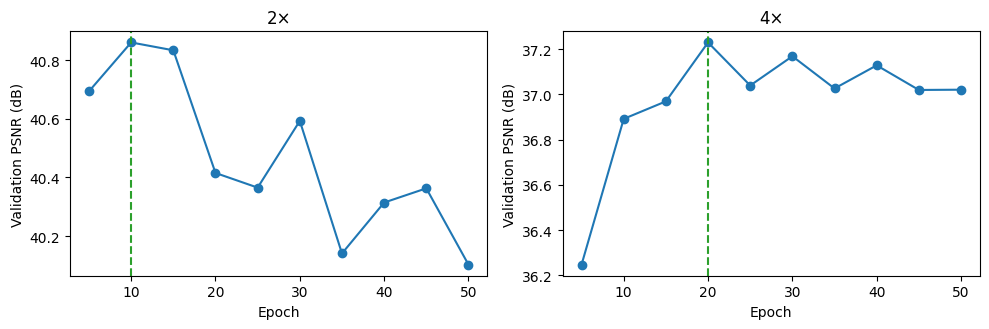

In [2]:
rows=[]
fig,axes=plt.subplots(1,len(RATES),figsize=(5*len(RATES),3.4),squeeze=False)
for axis,rate in zip(axes[0],RATES):
    selection=runs[rate][1]; candidates=selection['candidates']
    rows.append({'Rate':f'{rate}×','Selected epoch':selection['completed_epochs'],
                 'Step':selection['checkpoint_step'],'PSNR':selection['validation_metrics']['psnr'],
                 'SSIM':selection['validation_metrics']['ssim'],'NMSE':selection['validation_metrics']['nmse']})
    axis.plot([x['completed_epochs'] for x in candidates],[x[METHOD]['psnr'] for x in candidates],marker='o')
    axis.axvline(selection['completed_epochs'],color='tab:green',linestyle='--')
    axis.set(xlabel='Epoch',ylabel='Validation PSNR (dB)',title=f'{rate}×')
show_table(rows,[(key,key) for key in rows[0]])
plt.tight_layout(); plt.show()

## Held-out test results

In [3]:
rows=[]
for rate in RATES:
    test=runs[rate][3]; zf=test['zero_filled']; result=test[METHOD]
    rows.append({'Rate':f'{rate}×','ZF PSNR':zf['psnr'],'Full unrolled PSNR':result['psnr'],
                 'PSNR gain':result['psnr']-zf['psnr'],'ZF SSIM':zf['ssim'],
                 'Full unrolled SSIM':result['ssim'],'Complex NMSE':result['nmse'],
                 'Residual':result['measurement_residual'],'Seconds/slice':result['seconds_per_slice']})
show_table(rows,[(key,key) for key in rows[0]])

Rate,ZF PSNR,Full unrolled PSNR,PSNR gain,ZF SSIM,Full unrolled SSIM,Complex NMSE,Residual,Seconds/slice
2×,35.9877,40.3589,4.3712,0.9304,0.9445,0.0138,0.1965,0.3984
4×,29.7164,36.7149,6.9985,0.8295,0.9088,0.0378,0.1478,0.3989


## Validation-selected early-exit ablation

This ablation asks whether the trained ten-stage model should stop before its
final stage. The exit stage is selected **only on validation PSNR** (SSIM is the
tie-break); that one fixed stage is then evaluated on the held-out test split.
The original stage-10 result remains the primary model result.

In [4]:
early={}
for rate in RATES:
    root=runs[rate][0]/'evaluation/early_exit'
    selection_path=root/'selection.json'
    if not selection_path.exists():
        continue
    selection=read_json(selection_path)
    stage=int(selection['selected_stage']); step=int(selection['checkpoint_step'])
    test_path=root/'test'/f'stage-{stage:02d}-step-{step:07d}'/'summary.json'
    if test_path.exists(): early[rate]=(selection,read_json(test_path))

if not early:
    display(Markdown('Early-exit artifacts are not available yet. Run the validation-stage ablation for 2× and 4×, then rebuild this notebook.'))
else:
    fig,axes=plt.subplots(1,len(early),figsize=(5*len(early),3.4),squeeze=False)
    for axis,(rate,(selection,test)) in zip(axes[0],sorted(early.items())):
        candidates=sorted(selection['candidates'],key=lambda row:int(row['stage']))
        stages=[int(row['stage']) for row in candidates]
        psnr=[float(row['psnr']) for row in candidates]
        chosen=int(selection['selected_stage'])
        axis.plot(stages,psnr,marker='o')
        axis.axvline(chosen,color='tab:green',linestyle='--',label=f'Selected stage {chosen}')
        axis.set(xlabel='Output stage',ylabel='Validation PSNR (dB)',title=f'{rate}× validation')
        axis.set_xticks(stages); axis.legend()
    plt.tight_layout(); plt.show()

    rows=[]
    for rate,(selection,test) in sorted(early.items()):
        stage=int(selection['selected_stage'])
        final=runs[rate][3][METHOD]; selected=test[METHOD]
        for label,result in (('Stage 10 (primary)',final),(f'Stage {stage} (validation-selected)',selected)):
            rows.append({'Rate':f'{rate}×','Output':label,'PSNR':result['psnr'],'SSIM':result['ssim'],
                         'NMSE':result['nmse'],'Residual':result['measurement_residual'],
                         'Seconds/slice':result['seconds_per_slice']})
    show_table(rows,[(key,key) for key in rows[0]])

Early-exit artifacts are not available yet. Run the validation-stage ablation for 2× and 4×, then rebuild this notebook.

## Comparison with existing RDBM variants

In [5]:
comparison=[]
for rate in RATES:
    full=runs[rate][3][METHOD]
    rdbm_path=(DATA_ROOT/'derived'/('rdbm_full_bf16' if rate==4 else f'rdbm_{rate}x_bf16')/'evaluation/test/step-0094900/summary.json')
    if rdbm_path.exists():
        base=read_json(rdbm_path)['rdbm']
        comparison.append({'Rate':f'{rate}×','Model':'Original RDBM',**{k:base[k] for k in ('psnr','ssim','nmse','measurement_residual')}})
    comparison.append({'Rate':f'{rate}×','Model':'Full diffusion-unrolled',**{k:full[k] for k in ('psnr','ssim','nmse','measurement_residual')}})
if 4 in RATES:
    path=DATA_ROOT/'derived/unrolled_rdbm_4x_scratch/evaluation/test/step-0037960/summary.json'
    if path.exists():
        value=read_json(path)['unrolled_rdbm']
        comparison.insert(next(i for i,row in enumerate(comparison) if row['Rate']=='4×' and row['Model']=='Full diffusion-unrolled'),
                          {'Rate':'4×','Model':'Three-stage RDBM-derived',**{k:value[k] for k in ('psnr','ssim','nmse','measurement_residual')}})
formatted=[{'Rate':row['Rate'],'Model':row['Model'],'PSNR ↑':row['psnr'],'SSIM ↑':row['ssim'],
            'NMSE ↓':row['nmse'],'Residual ↓':row['measurement_residual']} for row in comparison]
show_table(formatted,[(key,key) for key in formatted[0]])

Rate,Model,PSNR ↑,SSIM ↑,NMSE ↓,Residual ↓
2×,Original RDBM,40.8276,0.9586,0.0199,0.1954
2×,Full diffusion-unrolled,40.3589,0.9445,0.0138,0.1965
4×,Original RDBM,35.6007,0.9207,0.0559,0.1450
4×,Three-stage RDBM-derived,36.3693,0.9088,0.0406,0.1487
4×,Full diffusion-unrolled,36.7149,0.9088,0.0378,0.1478


## Training trajectories

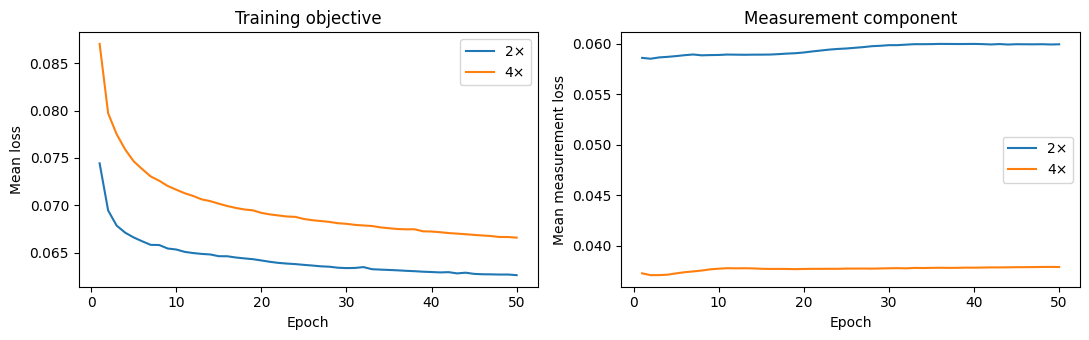

In [6]:
pattern=re.compile(r'epoch_complete=(\d+)/\d+ step=(\d+) mean_loss=([0-9.eE+-]+).*?mean_ssim_loss=([0-9.eE+-]+) mean_measurement=([0-9.eE+-]+)')
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
for rate in RATES:
    records=[match.groups() for line in (runs[rate][0]/'train.log').read_text().splitlines() if (match:=pattern.search(line))]
    records=list({int(row[0]):row for row in records}.values()); records.sort(key=lambda row:int(row[0]))
    epochs=[int(row[0]) for row in records]
    axes[0].plot(epochs,[float(row[2]) for row in records],label=f'{rate}×')
    axes[1].plot(epochs,[float(row[4]) for row in records],label=f'{rate}×')
axes[0].set(xlabel='Epoch',ylabel='Mean loss',title='Training objective')
axes[1].set(xlabel='Epoch',ylabel='Mean measurement loss',title='Measurement component')
for axis in axes: axis.legend()
plt.tight_layout(); plt.show()

## Reverse-diffusion and CG-SENSE progression

Matched sample: file_brain_AXT1POST_202_6000285:7 (central slice of the 4x test volume closest to the median volume-level PSNR gain)


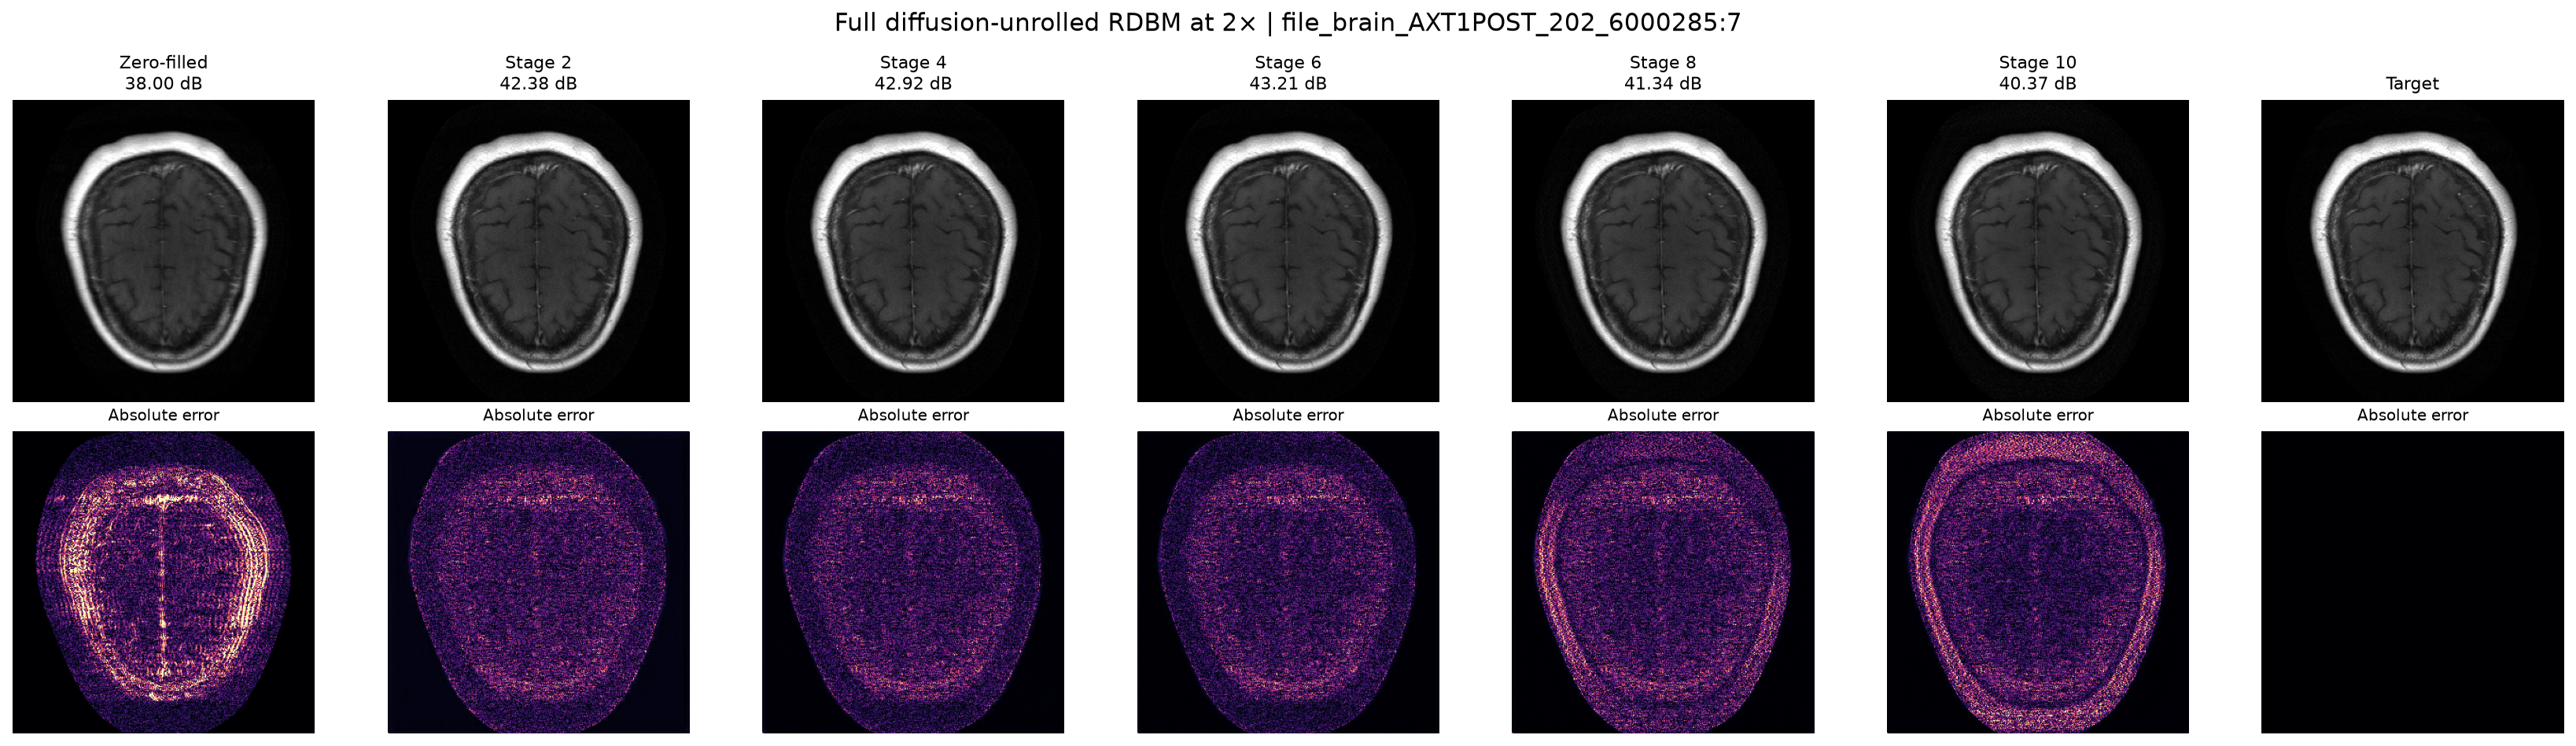

Stage,PSNR,SSIM,NMSE
Zero-filled,38.0017,0.9580,0.0052
Stage 2,42.3802,0.9645,0.0024
Stage 4,42.9224,0.9741,0.0020
Stage 6,43.2055,0.9774,0.0019
Stage 8,41.3448,0.9478,0.0028
Stage 10,40.3726,0.9284,0.0034


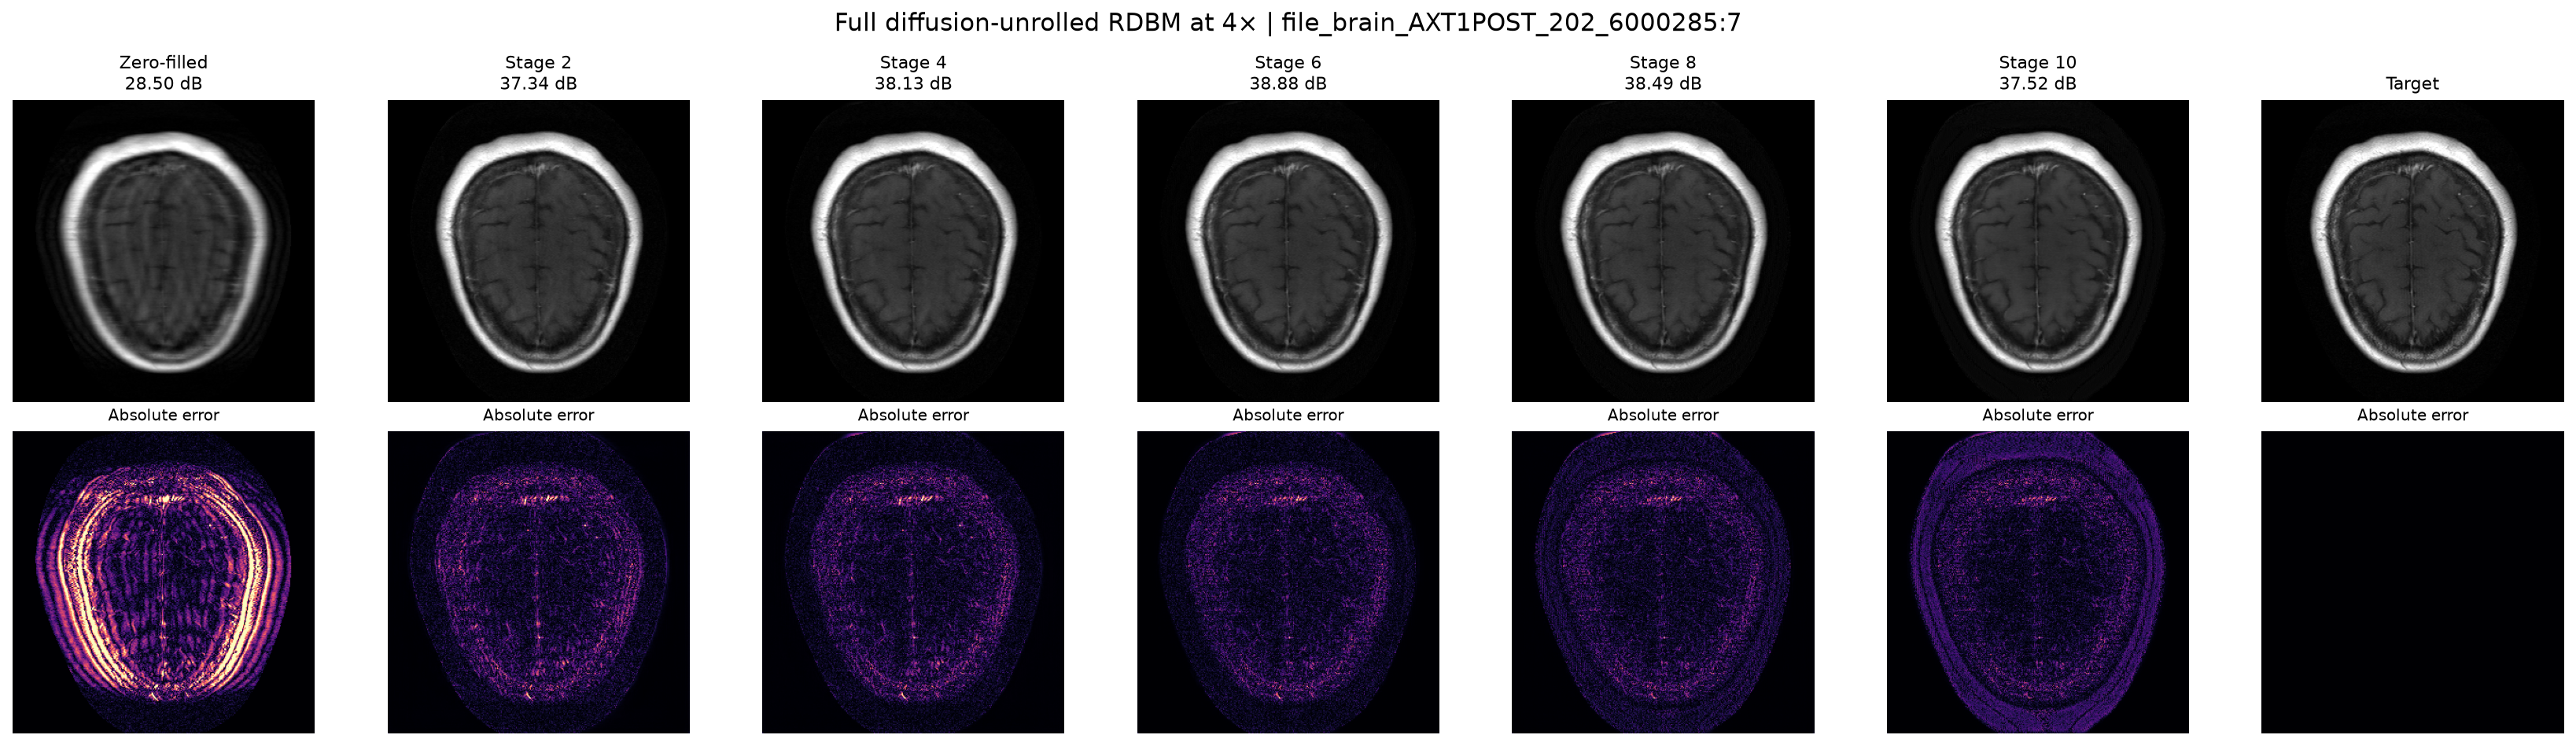

Stage,PSNR,SSIM,NMSE
Zero-filled,28.5016,0.8210,0.0370
Stage 2,37.3362,0.9372,0.0065
Stage 4,38.1322,0.9482,0.0054
Stage 6,38.8830,0.9547,0.0048
Stage 8,38.4902,0.9291,0.0055
Stage 10,37.5197,0.8962,0.0068


In [7]:
print(f"Matched sample: {progression['sample_id']} ({progression['selection_reason']})")
for rate in RATES:
    figure_path=ROOT/f'results/full_diffusion_unrolled_rdbm/qualitative/progression_{rate}x.png'
    if not figure_path.exists() or str(rate) not in progression.get('rates', {}):
        display(Markdown(f'**Missing qualitative artifacts for {rate}×. Re-run the result collector for this rate.**'))
        continue
    display(Image(filename=str(figure_path),width=2400))
    rows=[{'Stage':name,'PSNR':value['psnr'],'SSIM':value['ssim'],'NMSE':value['nmse']}
          for name,value in progression['rates'][str(rate)]['metrics'].items()]
    show_table(rows,[(key,key) for key in rows[0]])

## Interpretation

- The full model is a genuine ten-stage unrolling of the sampled RDBM trajectory,
  with explicit CG-SENSE consistency after every learned clean prediction.
- Checkpoint selection is validation-only; the test split is used once per rate.
- Intermediate stages need not improve monotonically because the complete trajectory
  is optimized jointly. Stage 10 is the reported reconstruction.
- The early-exit analysis is a separate ablation: its stage is chosen on validation,
  never from the qualitative example or test performance.
- Timing is hardware- and workload-dependent and is not a portable model property.